In [1]:
!pip install librosa numpy pandas scipy

  Using cached audioread-3.0.1-py3-none-any.whl.metadata (8.4 kB)
  Using cached numba-0.58.1-cp38-cp38-win_amd64.whl.metadata (2.8 kB)
  Using cached pooch-1.8.2-py3-none-any.whl.metadata (10 kB)
  Using cached soxr-0.3.7-cp38-cp38-win_amd64.whl.metadata (5.7 kB)
  Using cached lazy_loader-0.4-py3-none-any.whl.metadata (7.6 kB)
  Using cached msgpack-1.1.0-cp38-cp38-win_amd64.whl.metadata (8.6 kB)
  Using cached llvmlite-0.41.1-cp38-cp38-win_amd64.whl.metadata (4.9 kB)
Using cached audioread-3.0.1-py3-none-any.whl (23 kB)
Using cached lazy_loader-0.4-py3-none-any.whl (12 kB)
Using cached msgpack-1.1.0-cp38-cp38-win_amd64.whl (74 kB)
Using cached numba-0.58.1-cp38-cp38-win_amd64.whl (2.6 MB)
Using cached pooch-1.8.2-py3-none-any.whl (64 kB)
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 1.0/1.0 MB 12.0 MB/s eta 0:00:00
Using cached soxr-0.3.7-cp38-cp38-win_amd64.whl (184 kB)
Using cached llvmlite-0.41.1-cp38-cp38-win_amd

In [ ]:
import os
import subprocess

def convert_m4a_to_wav(input_dir, output_dir):
    for root, dirs, files in os.walk(input_dir):
        for file in files:
            if file.lower().endswith(".m4a"):
                input_path = os.path.join(root, file)

                # Create matching output path
                relative_path = os.path.relpath(root, input_dir)
                output_folder = os.path.join(output_dir, relative_path)
                os.makedirs(output_folder, exist_ok=True)

                # Build output .wav filename
                wav_filename = os.path.splitext(file)[0] + ".wav"
                output_path = os.path.join(output_folder, wav_filename)

                # Skip if already exists
                if os.path.exists(output_path):
                    print(f"Skipping (already exists): {output_path}")
                    continue

                # Convert
                try:
                    print(f"Converting: {input_path} → {output_path}")
                    subprocess.run([
                        "ffmpeg",
                        "-i", input_path,
                        "-acodec", "pcm_s16le",
                        "-ar", "44100",
                        output_path
                    ], check=True)
                except subprocess.CalledProcessError as e:
                    print(f"Error converting {input_path}: {e}")

# === Usage ===
input_folder = "DatasetM4A"
output_folder = "Dataset_wav"

convert_m4a_to_wav(input_folder, output_folder)


In [14]:
import os
import librosa
import numpy as np

# Path to your dataset folder
DATASET_PATH = "Dataset_wav/"

# Function to load all audio files and assign labels
def load_audio_files(dataset_path):
    data = []
    labels = []

    for label in os.listdir(dataset_path):
        label_path = os.path.join(dataset_path, label)
        if not os.path.isdir(label_path):
            continue

        for file in os.listdir(label_path):
            if file.endswith(".wav"):
                file_path = f"{label_path}/{file}"
                #file_path = os.path.join(label_path, file)
                #print(file_path)

                try:
                    audio, sr = librosa.load(file_path, sr=None)  # sr=None keeps original sample rate
                    data.append(audio)
                    labels.append(label)
                except Exception as e:
                    print(f"Error loading {file_path}: {e}")

    return data, labels

audio_data, audio_labels = load_audio_files(DATASET_PATH)
print(f"Loaded {len(audio_data)} samples.")


Loaded 82 samples.


In [16]:
from scipy.signal import butter, lfilter

def butter_bandpass(lowcut, highcut, fs, order=5):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return b, a

def apply_bandpass_filter(data, lowcut, highcut, fs):
    b, a = butter_bandpass(lowcut, highcut, fs)
    return lfilter(b, a, data)


In [28]:
# === Filter parameters ===
lowcut = 300    # Hz
highcut = 3000  # Hz
sr = 44100      # sample rate (same as your files)

# === Apply bandpass filter ===
filtered_audio_data = []

for audio in audio_data:
    filtered = apply_bandpass_filter(audio, lowcut, highcut, sr)
    filtered_audio_data.append(filtered)

print(f"Filtered {len(filtered_audio_data)} audio samples.")
audio_data = filtered_audio_data


Filtered 82 audio samples.


In [30]:
def segment_audio(audio, sr, window_size=2.0, overlap=0.5):
    segments = []
    samples_per_window = int(window_size * sr)
    step_size = int(samples_per_window * (1 - overlap))

    for start in range(0, len(audio) - samples_per_window + 1, step_size):
        end = start + samples_per_window
        segment = audio[start:end]
        segments.append(segment)

    return segments


In [31]:
segmented_audio = []
segmented_labels = []

window_size = 2.0  # seconds
overlap = 0.5

for audio, label in zip(audio_data, audio_labels):
    sr = 44100  # Your WAV files are at 44.1kHz after conversion
    segments = segment_audio(audio, sr, window_size, overlap)

    for segment in segments:
        segmented_audio.append(segment)
        segmented_labels.append(label)

print(f"Total segments created: {len(segmented_audio)}")
print(f"Example segment shape: {segmented_audio[0].shape}")
print(f"Labels example: {segmented_labels[:15]}")


Total segments created: 390
Example segment shape: (88200,)
Labels example: ['Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer', 'Beer']


In [32]:
def extract_features(segment, sr):
    # MFCCs
    mfccs = librosa.feature.mfcc(y=segment, sr=sr, n_mfcc=13)
    mfccs_mean = np.mean(mfccs, axis=1)

    # Spectral Centroid
    centroid = np.mean(librosa.feature.spectral_centroid(y=segment, sr=sr))

    # Spectral Bandwidth
    bandwidth = np.mean(librosa.feature.spectral_bandwidth(y=segment, sr=sr))

    # Spectral Contrast
    contrast = np.mean(librosa.feature.spectral_contrast(y=segment, sr=sr))

    # Zero Crossing Rate
    zcr = np.mean(librosa.feature.zero_crossing_rate(y=segment))

    # Combine all features into one array
    features = np.hstack([mfccs_mean, centroid, bandwidth, contrast, zcr])
    return features


In [33]:
all_features = []
all_labels_clean = []

sr = 44100  # Same sample rate as before

for segment, label in zip(segmented_audio, segmented_labels):
    features = extract_features(segment, sr)
    all_features.append(features)
    all_labels_clean.append(label)

all_features = np.array(all_features)
all_labels_clean = np.array(all_labels_clean)

print("Feature extraction complete!")
print("Feature shape:", all_features.shape)
print("Labels shape:", all_labels_clean.shape)


Feature extraction complete!
Feature shape: (390, 17)
Labels shape: (390,)


In [34]:
import pandas as pd

feature_columns = [f"mfcc_{i+1}" for i in range(13)] + ["centroid", "bandwidth", "contrast", "zcr"]

df = pd.DataFrame(all_features, columns=feature_columns)
df['label'] = all_labels_clean

df.to_csv("liquid_audio_features_filtered.csv", index=False)
print("✅ Feature dataset saved as 'liquid_audio_features.csv'")


✅ Feature dataset saved as 'liquid_audio_features.csv'


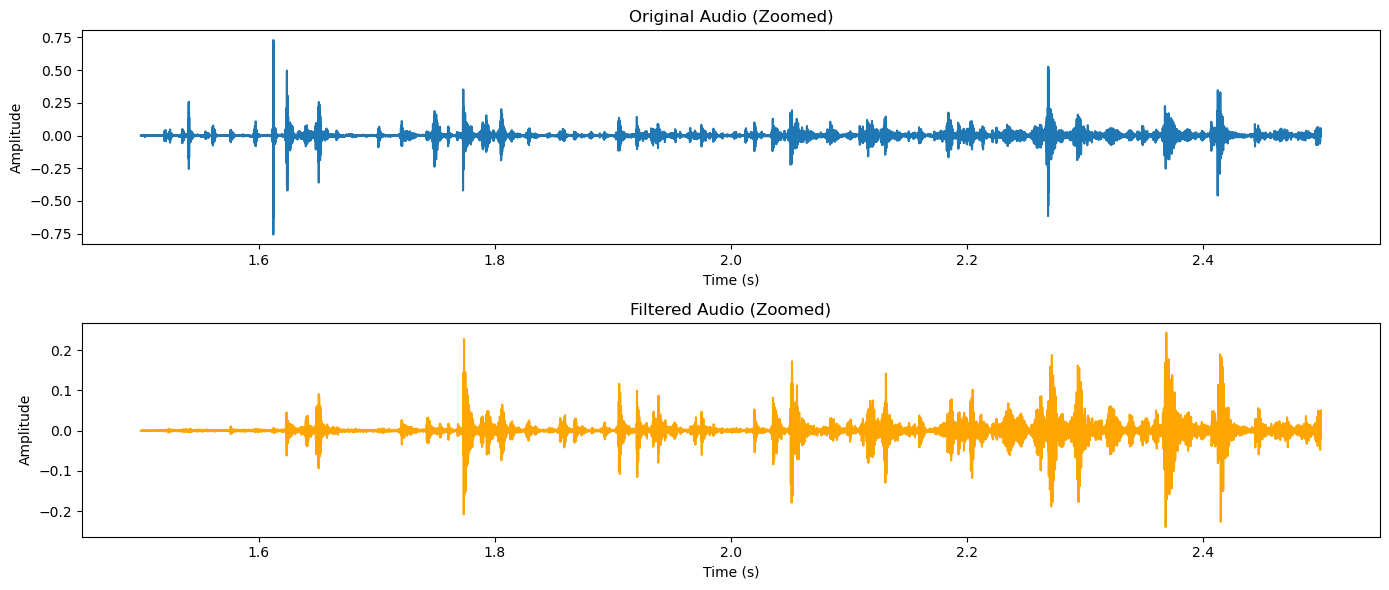

In [26]:
# Zoom range in seconds
start_time = 1.5
end_time = 2.5

# Convert to samples
start_sample = int(start_time * sr)
end_sample = int(end_time * sr)

# Slice both signals
raw_zoom = raw_audio[start_sample:end_sample]
filtered_zoom = filtered_audio[start_sample:end_sample]
time_zoom = np.linspace(start_time, end_time, end_sample - start_sample)

# Plot zoomed in waveforms
plt.figure(figsize=(14, 6))

plt.subplot(2, 1, 1)
plt.plot(time_zoom, raw_zoom)
plt.title("Original Audio (Zoomed)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")

plt.subplot(2, 1, 2)
plt.plot(time_zoom, filtered_zoom, color='orange')
plt.title("Filtered Audio (Zoomed)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()
